# 10 · Agregados y exploración del indicador v3

Se leen los resultados ya calculados. No se ejecuta el modelo ni se publica en AWS. Las conclusiones deben referirse a patrones de priorización, no a corrupción confirmada. No se exportan tablas o gráficos desde este notebook.


In [1]:
from pathlib import Path
import sys,json
from IPython.display import display,Markdown
ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'secop_pipeline').is_dir()),None)
if ROOT is None:raise RuntimeError('Abra el notebook dentro del proyecto.')
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import duckdb,pandas as pd,matplotlib.pyplot as plt
from secop_pipeline.indicador_v3 import latest_result,SIGNALS,lit
RESULTADOS=latest_result(ROOT)
reporte=json.loads(RESULTADOS.with_name('ejecucion.json').read_text(encoding='utf-8'))
if reporte.get('estado')!='COMPLETADA' or reporte.get('version')!='alertas-cd-3.0':raise ValueError('Ejecute primero el notebook 09 v3.')
db=duckdb.connect(config={'memory_limit':'1GB','threads':1})
db.execute(f'CREATE VIEW r AS SELECT * FROM read_parquet({lit(RESULTADOS)})')
display(reporte['parametros'])


{'cutoff': '2026-09-21',
 'coverage_start': '2017-01-01',
 'version': 'alertas-cd-3.0',
 'memory_mb': 2048,
 'threads': 1,
 'history_days': 365,
 'min_entity_contracts': 10,
 'min_supplier_contracts': 5,
 'c1_threshold': 0.4,
 'c2_threshold': 0.25,
 'c3_threshold': 0.8,
 'absolute_value_cap': 10000000000000,
 'median_value_factor': 1000,
 'v1_reference_years': 2,
 'v1_min_reference': 30,
 'v1_z_threshold': 3.5,
 'v2_days': 30,
 'v2_min_contracts': 3,
 'p2_min_segments': 3,
 'review_top_k_per_quarter': 2000,
 'minimum_priority_score': 0.0}

## 1. Clasificación y cobertura

**Por qué:** el porcentaje de alertas depende del cupo y de la información evaluable. **Cómo:** conteos y porcentajes de todas las filas; NO_EVALUABLE se mantiene separado. La tabla de dimensiones usa señales/evaluados y evaluados/total, denominadores distintos. No se suman las alertas de dimensiones como si fueran contratos únicos.


,clasificacion,contratos,porcentaje
0,NO_EVALUABLE,4125049,94.7477
1,NO_ALERTA,186084,4.2741
2,ALERTA,42587,0.9782


,dimension,total,evaluados,alertas,sin_senal,no_evaluables,cobertura_pct,senal_entre_evaluados_pct
0,C1,4353720,4330105,206,4329899,23615,99.457590,0.004757
1,C2,4353720,4343765,369,4343396,9955,99.771345,0.008495
2,C3,4353720,262261,69082,193179,4091459,6.023837,26.340935
3,V1,4353720,4246400,13340,4233060,107320,97.534982,0.314148
4,V2,4353720,4332972,13057,4319915,20748,99.523442,0.301341
5,P1,4353720,4349673,1024545,3325128,4047,99.907045,23.554529
6,P2,4353720,248202,57264,190938,4105518,5.700918,23.071530


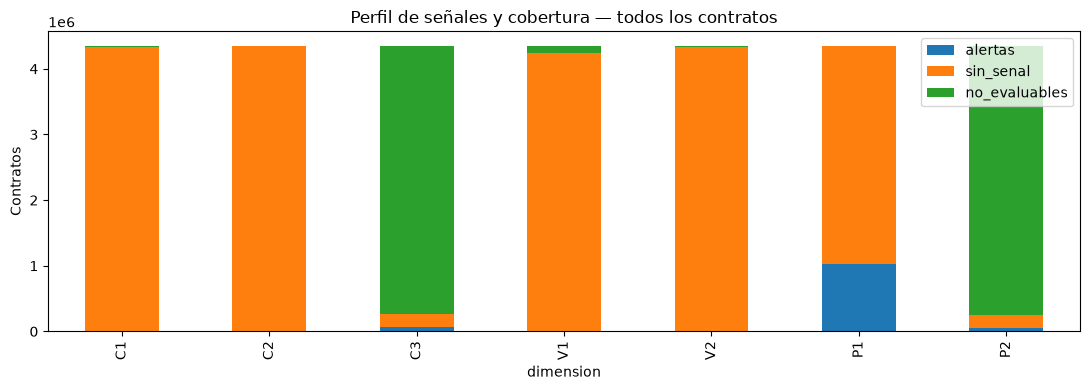

Conclusión descriptiva: {'NO_EVALUABLE': 4125049, 'NO_ALERTA': 186084, 'ALERTA': 42587}
Dimensión con menor cobertura: P2


In [2]:
clases=db.execute("SELECT clasificacion,count(*) contratos,round(100.0*count(*)/sum(count(*)) OVER(),4) porcentaje FROM r GROUP BY 1 ORDER BY 2 DESC").fetchdf()
dimensiones=pd.DataFrame(reporte['resumen']['dimensiones']).T.rename_axis('dimension').reset_index()
dimensiones['cobertura_pct']=100*dimensiones.evaluados/dimensiones.total
dimensiones['senal_entre_evaluados_pct']=100*dimensiones.alertas/dimensiones.evaluados.replace(0,float('nan'))
display(clases);display(dimensiones)
dimensiones.set_index('dimension')[['alertas','sin_senal','no_evaluables']].plot.bar(stacked=True,figsize=(11,4),title='Perfil de señales y cobertura — todos los contratos')
plt.ylabel('Contratos');plt.tight_layout();plt.show()
print('Conclusión descriptiva:',reporte['resumen']['clasificaciones'])
print('Dimensión con menor cobertura:',dimensiones.sort_values('cobertura_pct').iloc[0]['dimension'])


## 2. Puntaje y capacidad de revisión

**Por qué:** el puntaje es discreto aunque esté entre 0 y 1; hay empates. **Cómo:** barras por puntaje exacto y tabla trimestral. La clasificación depende de top K dentro del trimestre; no de un umbral fijo de probabilidad. Una comparación entre años debe considerar cobertura y años parciales.


,puntaje,contratos
0,0.000000,125966
1,0.111111,53842
2,0.166667,35474
3,0.222222,16
4,0.277778,6320
5,0.333333,4783
6,0.388889,46
7,0.444444,1927
8,0.500000,153
9,0.555556,29


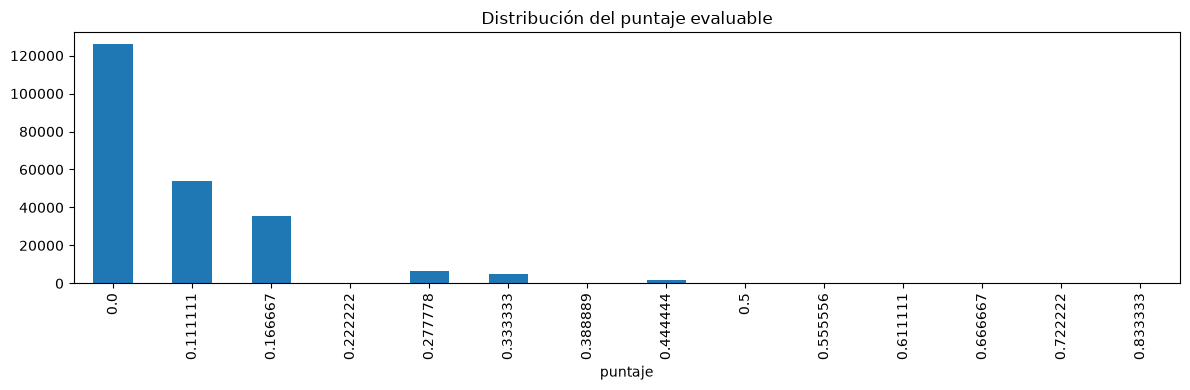

,periodo_revision,total,evaluables,priorizados,menor_puntaje_priorizado
0,2017-07-01,124,0,0,NaN
1,2017-10-01,3923,0,0,NaN
2,2018-01-01,41132,30,16,0.111111
3,2018-04-01,4253,6,3,0.166667
4,2018-07-01,25513,107,58,0.111111
5,2018-10-01,21275,85,50,0.111111
6,2019-01-01,82807,297,143,0.111111
7,2019-04-01,2037,24,15,0.166667
8,2019-07-01,602,5,2,0.166667
9,2019-10-01,218,1,0,NaN


,anio,anio_completo,contratos
0,2017,True,4047
1,2018,True,92173
2,2019,True,85664
3,2020,True,273892
4,2021,True,451912
5,2022,True,566007
6,2023,True,651894
7,2024,True,734821
8,2025,True,802117
9,2026,False,691193


Conclusión: el límite inferior de selección varía por trimestre; los empates no implican distinto riesgo.


In [3]:
puntajes=db.execute('SELECT round(puntaje,6) puntaje,count(*) contratos FROM r WHERE puntaje IS NOT NULL GROUP BY 1 ORDER BY 1').fetchdf()
display(puntajes)
if not puntajes.empty:
    puntajes.plot.bar(x='puntaje',y='contratos',figsize=(12,4),legend=False,title='Distribución del puntaje evaluable')
    plt.tight_layout();plt.show()
trimestres=db.execute("SELECT periodo_revision,count(*) total,count(puntaje) evaluables,count(*) FILTER(WHERE clasificacion='ALERTA') priorizados,min(puntaje) FILTER(WHERE clasificacion='ALERTA') menor_puntaje_priorizado FROM r GROUP BY 1 ORDER BY 1").fetchdf()
display(trimestres)
display(db.execute('SELECT anio,anio_completo,count(*) contratos FROM r GROUP BY 1,2 ORDER BY 1').fetchdf())
print('Conclusión: el límite inferior de selección varía por trimestre; los empates no implican distinto riesgo.')


## 3. Calidad monetaria y motivos de no evaluación

**Por qué:** los errores de registro no deben transformarse en alertas V1. **Cómo:** tabla de motivos de valores inválidos y desglose por señal. Los contratos permanecen en el universo; solo se excluyen de las referencias monetarias y de la evaluación V1.


In [4]:
display(db.execute("SELECT motivo_valor_invalido,count(*) contratos FROM r GROUP BY 1 ORDER BY 2 DESC").fetchdf())
for s in SIGNALS:
    print(s.upper())
    display(db.execute(f'SELECT motivo_{s} motivo,count(*) contratos FROM r WHERE {s} IS NULL GROUP BY 1 ORDER BY 2 DESC').fetchdf())
print('Conclusión: revisar estos motivos antes de reducir mínimos o interpretar pocos contratos priorizados.')


,motivo_valor_invalido,contratos
0,None,4317622
1,no_positivo,35664
2,supera_factor_mediana,411
3,supera_tope_absoluto,23


C1


,motivo,contratos
0,pocos_contratos_entidad,19568
1,historia_insuficiente,4047


C2


,motivo,contratos
0,pocos_contratos_entidad,9955


...

P1


,motivo,contratos
0,historia_insuficiente,4047


P2


,motivo,contratos
0,pocos_contratos_proveedor,4059583
1,categorias_incompletas_historia,21140
2,sin_categoria,20748
3,historia_insuficiente,4047


Conclusión: revisar estos motivos antes de reducir mínimos o interpretar pocos contratos priorizados.


## 4. Dependencia entre señales y red complementaria

**Por qué:** C1/C2/C3 pueden aportar información redundante; grado y frecuencia describen volumen, no culpabilidad. **Cómo:** correlación de señales binarias sobre pares evaluables (coeficiente phi); se muestran tamaños de muestra y NULL si no hay variación. Las medidas de red se resumen por año. No se usan para modificar el puntaje.


In [5]:
from itertools import combinations
pairs=[]
for a,b in combinations(SIGNALS,2):
    n,phi=db.execute(f'SELECT count(*),corr({a},{b}) FROM r WHERE {a} IS NOT NULL AND {b} IS NOT NULL').fetchone()
    pairs.append({'senal_a':a,'senal_b':b,'pares_evaluables':n,'phi':phi})
display(pd.DataFrame(pairs))
red=RESULTADOS.with_name('red_proveedores.parquet')
display(db.execute(f'SELECT anio,count(*) proveedores,median(grado_entidades) mediana_entidades,quantile_cont(grado_entidades,.95) p95_entidades,median(grado_ponderado) mediana_contratos FROM read_parquet({lit(red)}) GROUP BY 1 ORDER BY 1').fetchdf())
print('Hipótesis a contrastar: C1/C2 redundantes; concentración y dependencia no equivalentes; diversidad puede reflejar especialización amplia legítima.')
db.close()


,senal_a,senal_b,pares_evaluables,phi
0,c1,c2,4328737,0.542443
1,c1,c3,259917,0.040940
2,c1,v1,4228849,0.007536
3,c1,v2,4309588,0.054450
4,c1,p1,4330105,-0.003418
5,c1,p2,246161,0.030224
6,c2,c3,260268,0.034957
7,c2,v1,4237733,0.007405
8,c2,v2,4323141,0.031077
9,c2,p1,4339952,-0.000873


,anio,proveedores,mediana_entidades,p95_entidades,mediana_contratos
0,2017,3959,1.0,1.0,1.0
1,2018,77977,1.0,1.0,1.0
2,2019,81732,1.0,1.0,1.0
3,2020,206411,1.0,2.0,1.0
4,2021,319970,1.0,2.0,1.0
5,2022,380939,1.0,2.0,1.0
6,2023,408837,1.0,2.0,1.0
7,2024,458966,1.0,2.0,1.0
8,2025,492339,1.0,2.0,1.0
9,2026,472583,1.0,2.0,1.0


Hipótesis a contrastar: C1/C2 redundantes; concentración y dependencia no equivalentes; diversidad puede reflejar especialización amplia legítima.
